## Brain Tumor

Test

In [3]:
pip install pandas matplotlib pillow seaborn

Step 1 — Inspect the dataset and count the images
This gives you the basic dataset inventory and reveals unexpected file types.

In [4]:

from pathlib import Path
from collections import Counter
import pandas as pd

# Change this to the directory containing your four class folders
DATA_DIR = Path("../archive/data")

classes = ["normal", "glioma_tumor", "meningioma_tumor", "pituitary_tumor"]
valid_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

records = []
unexpected_files = []

for class_name in classes:
    class_dir = DATA_DIR / class_name

    if not class_dir.is_dir():
        print(f"WARNING: Folder not found: {class_dir}")
        continue

    for file_path in class_dir.rglob("*"):
        if not file_path.is_file():
            continue

        if file_path.suffix.lower() not in valid_extensions:
            unexpected_files.append(str(file_path))
            continue

        records.append({
            "filename": file_path.name,
            "filepath": str(file_path),
            "class": class_name,
            "extension": file_path.suffix.lower()
        })

df = pd.DataFrame(records)

print("Total number of images:", len(df))
print("\nImages per class:")
print(df["class"].value_counts().reindex(classes, fill_value=0))

print("\nFile formats:")
print(df["extension"].value_counts())

print("\nUnexpected files:", len(unexpected_files))
print(unexpected_files[:20])


Total number of images: 3096

Images per class:
class
normal              438
glioma_tumor        901
meningioma_tumor    913
pituitary_tumor     844
Name: count, dtype: int64

File formats:
extension
.jpg    3096
Name: count, dtype: int64

Unexpected files: 0
[]


What to document:
- Total number of images found.
- Number of images per class.
- File formats used.
- Whether the folder structure matches expectations.
- Any missing class folders or unexpected files.
Save this inventory for reuse during Data Preparation.

Step 2 — Visualise the class distribution
The folder counts are useful, but a chart makes imbalances much easier to explain in your report.

                  Images  Percentage
class                               
normal               438       14.15
glioma_tumor         901       29.10
meningioma_tumor     913       29.49
pituitary_tumor      844       27.26


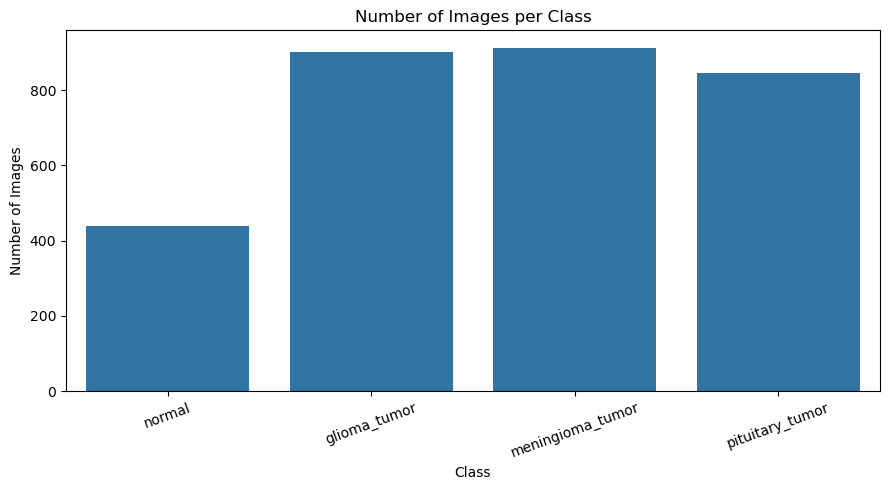

In [5]:

import matplotlib.pyplot as plt
import seaborn as sns

class_counts = (
    df["class"]
    .value_counts()
    .reindex(classes, fill_value=0)
)

class_percentages = class_counts / class_counts.sum() * 100

distribution = pd.DataFrame({
    "Images": class_counts,
    "Percentage": class_percentages.round(2)
})

print(distribution)

plt.figure(figsize=(9, 5))
sns.barplot(x=class_counts.index, y=class_counts.values)

plt.title("Number of Images per Class")
plt.xlabel("Class")
plt.ylabel("Number of Images")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


Interpret the result by asking:
- Are all four classes represented sufficiently?
- Is one class substantially larger than another?
- Will you need to consider class weighting or other imbalance-handling techniques later?
Don't automatically balance the dataset at this stage. First establish whether imbalance exists and how significant it is.

Step 3 — Display example images from every class
This is one of the most important steps because image recognition is the heart of the challenge.

Display a grid with 8 randomly selected images per class. Keep the images at their original display aspect ratio so you can inspect them properly.

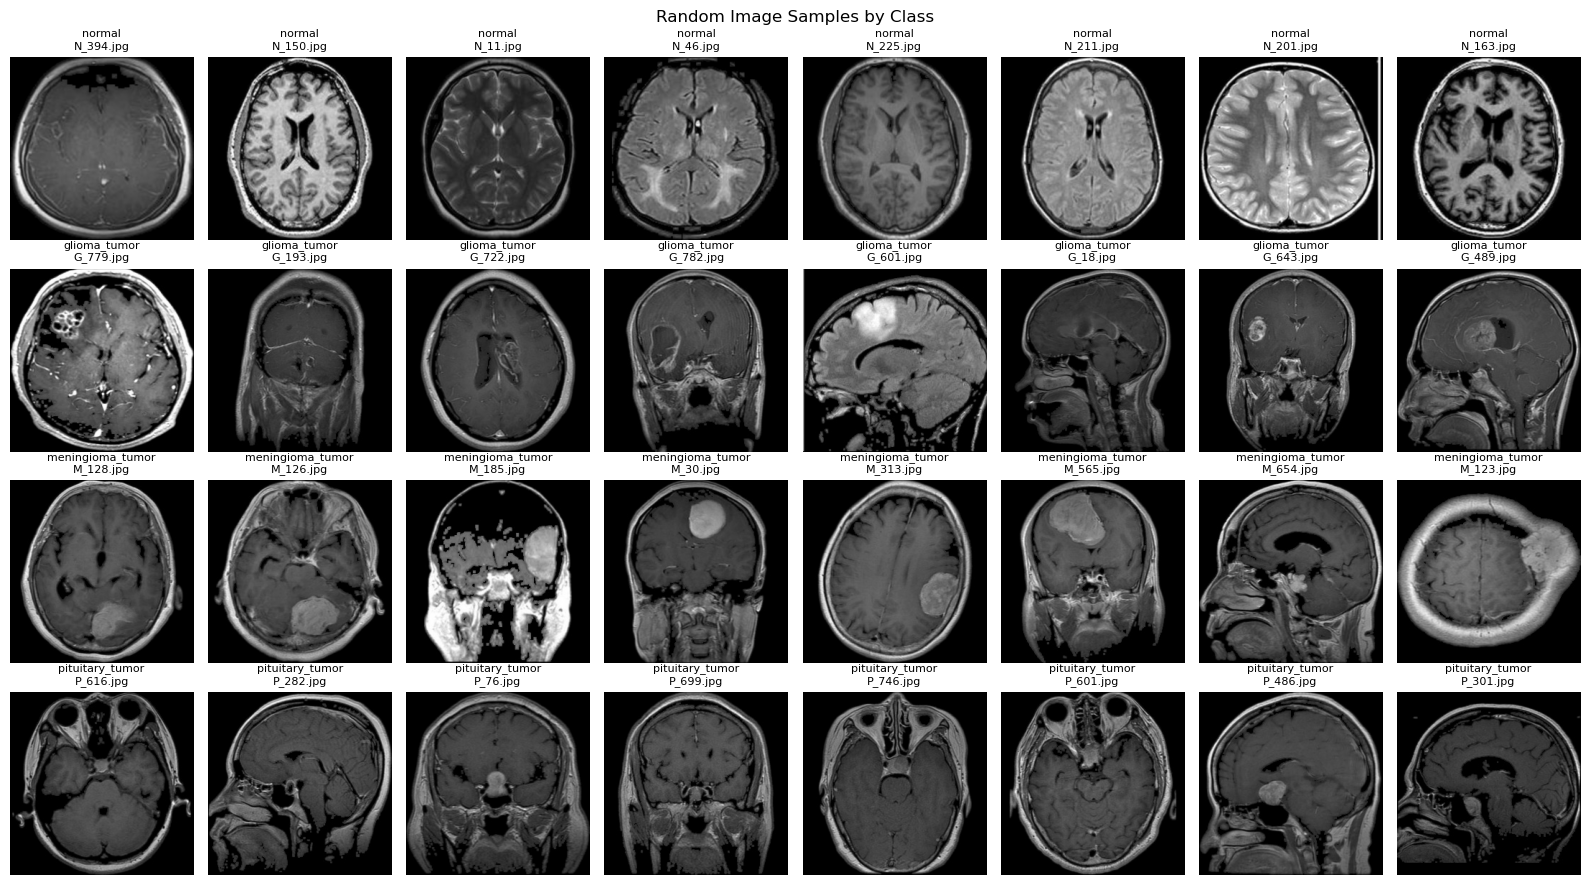

In [6]:

import random
import math
import matplotlib.pyplot as plt
from PIL import Image

random.seed(42)

n_per_class = 8
fig, axes = plt.subplots(
    len(classes), n_per_class,
    figsize=(16, 9)
)

for row, class_name in enumerate(classes):
    class_images = df.loc[
        df["class"] == class_name,
        ["filepath", "filename"]
    ].to_dict("records")

    selected = random.sample(
        class_images,
        min(n_per_class, len(class_images))
    )

    for col in range(n_per_class):
        ax = axes[row, col]

        if col < len(selected):
            image = selected[col]
            with Image.open(image["filepath"]) as img:
                ax.imshow(img.copy(), cmap="gray")
            ax.set_title(
                f"{class_name}\n{image['filename']}",
                fontsize=8
            )

        ax.axis("off")

        if col == 0:
            ax.set_ylabel(
                class_name,
                rotation=90,
                fontsize=11
            )

plt.suptitle("Random Image Samples by Class")
plt.tight_layout()
plt.show()


Inspect the grid and write down your observations.
Aspect	What to look for
Anatomical appearance	Are similar brain structures visible across classes?
Tumour visibility	Are apparent abnormalities visible in some examples?
Orientation	Do images show different views or orientations?
Contrast and brightness	Do images vary in intensity or background?
Image quality	Are some blurry, noisy, cropped or difficult to interpret?
Potential shortcuts	Do certain classes have distinctive borders, text, colours or backgrounds?

Important: don't assume that every tumour will be visually obvious. Some images may be ambiguous even to a non-expert, and visual inspection alone cannot verify the diagnosis.

Step 4 — Investigate image dimensions, modes and quality
Even if the images are all stored in folders, their technical properties might differ. This code collects their dimensions, image modes and pixel statistics and flags files that cannot be opened.

In [7]:

from PIL import Image, ImageStat
import numpy as np

image_info = []
corrupted_files = []

for _, row in df.iterrows():
    try:
        with Image.open(row["filepath"]) as img:
            img.load()

            arr = np.asarray(img)

            image_info.append({
                "filepath": row["filepath"],
                "class": row["class"],
                "width": img.width,
                "height": img.height,
                "mode": img.mode,
                "format": img.format,
                "min_pixel": float(arr.min()),
                "max_pixel": float(arr.max()),
                "mean_pixel": float(arr.mean()),
                "std_pixel": float(arr.std())
            })

    except Exception as e:
        corrupted_files.append({
            "filepath": row["filepath"],
            "error": str(e)
        })

image_df = pd.DataFrame(image_info)

print("Readable images:", len(image_df))
print("Unreadable images:", len(corrupted_files))

print("\nImage modes:")
print(image_df["mode"].value_counts())

print("\nImage formats:")
print(image_df["format"].value_counts())

print("\nDimensions:")
print(
    image_df.groupby("class")
    .agg(
        images=("filepath", "count"),
        unique_widths=("width", "nunique"),
        unique_heights=("height", "nunique"),
        min_width=("width", "min"),
        max_width=("width", "max"),
        min_height=("height", "min"),
        max_height=("height", "max")
    )
)

print("\nPixel statistics:")
print(
    image_df[
        ["min_pixel", "max_pixel", "mean_pixel", "std_pixel"]
    ].describe()
)

print("\nUnreadable files:")
print(corrupted_files[:10])


Readable images: 3096
Unreadable images: 0

Image modes:
mode
RGB    3096
Name: count, dtype: int64

Image formats:
format
JPEG    3096
Name: count, dtype: int64

Dimensions:
                  images  unique_widths  unique_heights  min_width  max_width  \
class                                                                           
glioma_tumor         901              1               1        256        256   
meningioma_tumor     913              1               1        256        256   
normal               438              1               1        256        256   
pituitary_tumor      844              1               1        256        256   

                  min_height  max_height  
class                                     
glioma_tumor             256         256  
meningioma_tumor         256         256  
normal                   256         256  
pituitary_tumor          256         256  

Pixel statistics:
       min_pixel    max_pixel   mean_pixel    std_pixel
count

How to interpret this:
- Dimensions: If images have different widths and heights, you will probably need to resize them to a consistent model input size.
- Modes: L generally means grayscale, RGB means three colour channels, and RGBA includes an alpha channel. Different modes may require consistent conversion.
- Pixel values: Differences in mean intensity or standard deviation can reveal variation in brightness and contrast. These are clues, not proof of a quality problem.
- Unreadable images: These need to be investigated and handled during Data Preparation.
If all the images are already 256 × 256 pixels, that is useful information to record. It doesn't mean that every other preprocessing step is unnecessary.

Step 5 — Compare technical image characteristics across classes
This step is particularly valuable for image recognition. A model might learn differences in contrast, borders or image sources rather than actual tumour characteristics.

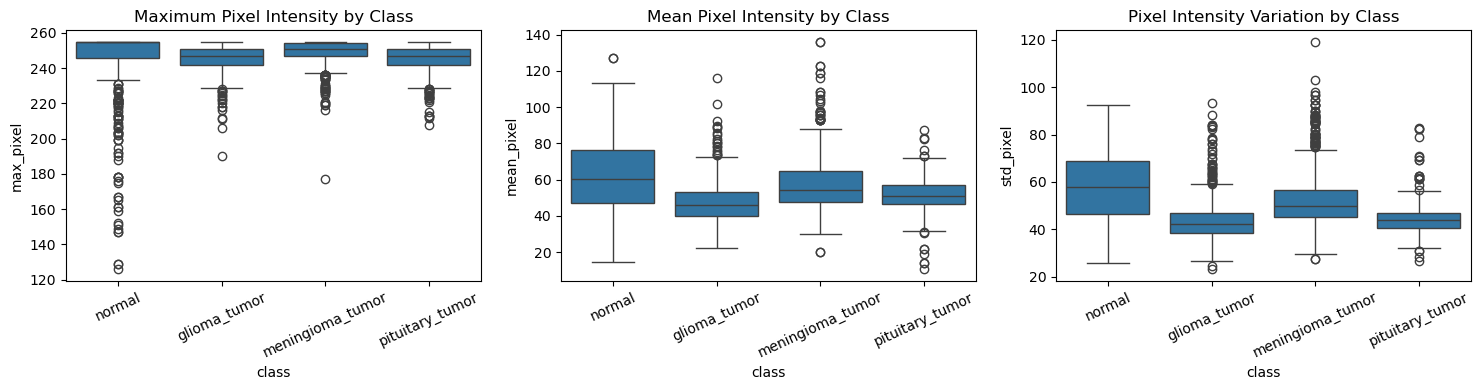

In [8]:


fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.boxplot(
    data=image_df,
    x="class",
    y="max_pixel",
    ax=axes[0]
)
axes[0].set_title("Maximum Pixel Intensity by Class")
axes[0].tick_params(axis="x", rotation=25)
sns.boxplot(
    data=image_df,
    x="class",
    y="mean_pixel",
    ax=axes[1]
)
axes[1].set_title("Mean Pixel Intensity by Class")
axes[1].tick_params(axis="x", rotation=25)

sns.boxplot(
    data=image_df,
    x="class",
    y="std_pixel",
    ax=axes[2]
)
axes[2].set_title("Pixel Intensity Variation by Class")
axes[2].tick_params(axis="x", rotation=25)

plt.tight_layout()
plt.show()


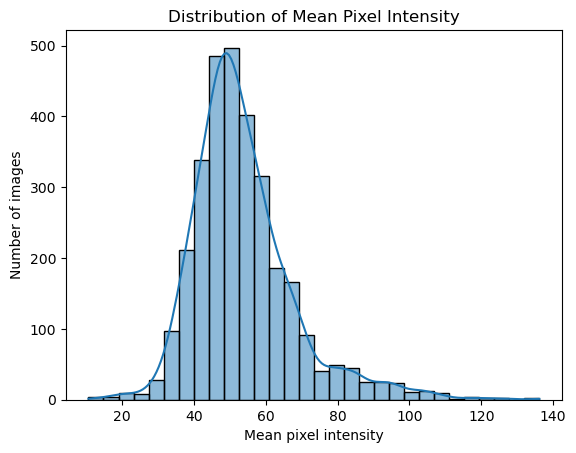

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.histplot(
    data=image_df,
    x="mean_pixel",
    bins=30,
    kde=True
)

plt.title("Distribution of Mean Pixel Intensity")
plt.xlabel("Mean pixel intensity")
plt.ylabel("Number of images")
plt.show()

If one class has noticeably different pixel statistics, investigate the sample images and their origins. This could be a legitimate characteristic, a difference in image acquisition, or an artefact of how the dataset was assembled.

Do not automatically remove or normalise away these differences before understanding them.

Step 6 — Investigate duplicate images and data leakage
This is an important part of Data Understanding that is often skipped in beginner projects.

If the same image occurs in both training and test data, the model could appear to perform better than it really does. Exact duplicates can be detected using file hashes.

In [10]:

import hashlib
from collections import defaultdict

hash_to_files = defaultdict(list)

for _, row in df.iterrows():
    path = row["filepath"]

    with open(path, "rb") as f:
        digest = hashlib.sha256(f.read()).hexdigest()

    hash_to_files[digest].append({
        "filepath": path,
        "class": row["class"]
    })

duplicates = {
    digest: files
    for digest, files in hash_to_files.items()
    if len(files) > 1
}

print("Unique image hashes:", len(hash_to_files))
print("Groups containing exact duplicates:", len(duplicates))

for digest, files in list(duplicates.items())[:10]:
    print("\nDuplicate group:")
    for file in files:
        print(file["class"], file["filepath"])

    if len({file["class"] for file in files}) > 1:
        print("WARNING: Identical files have different labels!")


Unique image hashes: 2845
Groups containing exact duplicates: 217

Duplicate group:
normal ..\archive\data\normal\N_101.jpg
normal ..\archive\data\normal\N_115.jpg
normal ..\archive\data\normal\N_117.jpg

Duplicate group:
normal ..\archive\data\normal\N_102.jpg
normal ..\archive\data\normal\N_116.jpg
normal ..\archive\data\normal\N_344.jpg
normal ..\archive\data\normal\N_347.jpg

Duplicate group:
normal ..\archive\data\normal\N_103.jpg
normal ..\archive\data\normal\N_108.jpg
normal ..\archive\data\normal\N_121.jpg

Duplicate group:
normal ..\archive\data\normal\N_104.jpg
normal ..\archive\data\normal\N_107.jpg

Duplicate group:
normal ..\archive\data\normal\N_105.jpg
normal ..\archive\data\normal\N_110.jpg
normal ..\archive\data\normal\N_343.jpg
normal ..\archive\data\normal\N_346.jpg

Duplicate group:
normal ..\archive\data\normal\N_109.jpg
normal ..\archive\data\normal\N_385.jpg

Duplicate group:
normal ..\archive\data\normal\N_11.jpg
normal ..\archive\data\normal\N_12.jpg
normal ..\

In [11]:

import pandas as pd

duplicate_counts = {
    class_name: {
        "total_images": int((df["class"] == class_name).sum()),
        "duplicate_images": 0
    }
    for class_name in classes
}

# Tel alle afbeeldingen die deel uitmaken van een duplicaatgroep
for digest, files in duplicates.items():
    for file in files:
        class_name = file["class"]
        duplicate_counts[class_name]["duplicate_images"] += 1

# Resultaten omzetten naar een DataFrame
duplicate_df = pd.DataFrame.from_dict(
    duplicate_counts,
    orient="index"
)

duplicate_df["unique_images"] = (
    duplicate_df["total_images"]
    - duplicate_df["duplicate_images"]
)

duplicate_df["duplicate_percentage"] = (
    duplicate_df["duplicate_images"]
    / duplicate_df["total_images"]
    * 100
).round(2)

print(duplicate_df)


                  total_images  duplicate_images  unique_images  \
normal                     438               222            216   
glioma_tumor               901                32            869   
meningioma_tumor           913               194            719   
pituitary_tumor            844                20            824   

                  duplicate_percentage  
normal                           50.68  
glioma_tumor                      3.55  
meningioma_tumor                 21.25  
pituitary_tumor                   2.37  


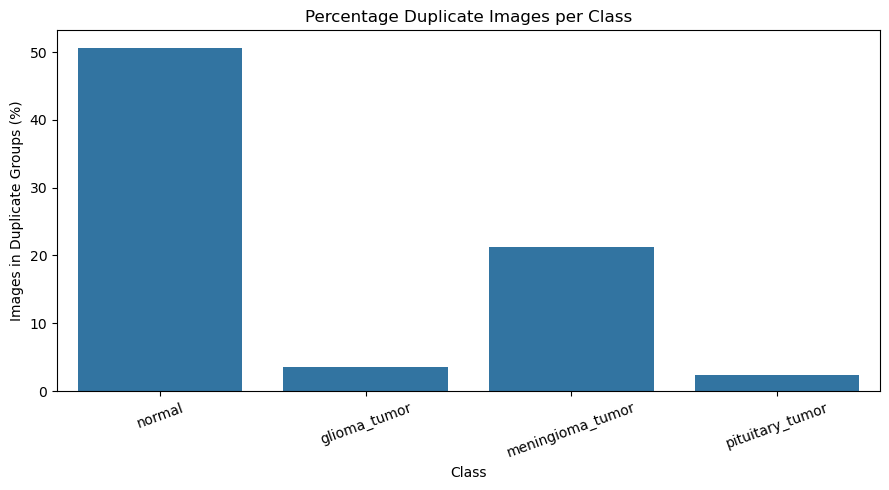

In [12]:

import matplotlib.pyplot as plt
import seaborn as sns

plot_df = duplicate_df.reset_index(names="class")

plt.figure(figsize=(9, 5))

sns.barplot(
    data=plot_df,
    x="class",
    y="duplicate_percentage"
)

plt.title("Percentage Duplicate Images per Class")
plt.xlabel("Class")
plt.ylabel("Images in Duplicate Groups (%)")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


In [13]:

from PIL import Image
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages
from pathlib import Path
import math

# 'duplicates' is the dictionary created by your SHA-256 analysis
output_pdf = Path("duplicate_images_report.pdf")

groups = list(duplicates.items())
groups_per_page = 6

with PdfPages(output_pdf) as pdf:
    for start in range(0, len(groups), groups_per_page):
        batch = groups[start:start + groups_per_page]

        # Include every image in each group
        max_images = max(len(files) for _, files in batch)

        fig, axes = plt.subplots(
            len(batch),
            max_images,
            figsize=(max(8, max_images * 2.2), len(batch) * 2.6),
            squeeze=False
        )

        for row_idx, (digest, files) in enumerate(batch):
            for col_idx in range(max_images):
                ax = axes[row_idx, col_idx]
                ax.axis("off")

                if col_idx < len(files):
                    file_info = files[col_idx]
                    path = file_info["filepath"]

                    try:
                        with Image.open(path) as img:
                            ax.imshow(img.convert("RGB"))

                        ax.set_title(
                            Path(path).name,
                            fontsize=8
                        )

                    except Exception as e:
                        ax.text(
                            0.5, 0.5,
                            f"Could not load:\n{e}",
                            ha="center",
                            va="center"
                        )

                elif col_idx == 0:
                    ax.text(0.5, 0.5, "No image",
                            ha="center", va="center")

            # Label the group on the leftmost image
            axes[row_idx, 0].set_ylabel(
                f"Group {start + row_idx + 1}\n"
                f"{len(files)} copies",
                fontsize=9
            )

        fig.suptitle(
            f"Exact Duplicate Images "
            f"(Groups {start + 1}–{start + len(batch)})",
            fontsize=14
        )

        plt.tight_layout()
        pdf.savefig(fig, bbox_inches="tight")
        plt.close(fig)

print(f"Created: {output_pdf.resolve()}")
print(f"Duplicate groups visualised: {len(groups)}")
print(
    "Total files in duplicate groups:",
    sum(len(files) for _, files in groups)
)


Created: C:\Users\rickv\School\Jaar3\minor\Challenge\Brain-Tumor\brain_tumors\duplicate_images_report.pdf
Duplicate groups visualised: 217
Total files in duplicate groups: 468


This checks exact duplicates only. Two visually identical images can have different file hashes if their compression or metadata differs.

For near-duplicates, you could later use perceptual hashing. Also check whether patient identifiers or source metadata are available. If multiple images originate from the same patient, a random image-level split could put images from the same patient into both training and test sets, causing leakage.

If patient identities aren't available, explicitly document this limitation rather than claiming that the split is patient-independent.